# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** I Gusti Ngurah Abre Pramana
- **Email:** ds014b6y0751@student.devacademy.id
- **ID Dicoding:** abretobaron

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa yang menghasilkan total revenue (harga produk, di luar ongkir) tertinggi dan terendah pada pesanan *delivered* periode Januari 2017 - Agustus 2018, dan berapa persen kontribusi 5 kategori teratas terhadap total revenue, agar tim dapat memprioritaskan stok, promosi, dan akuisisi seller?
- **Pertanyaan 2:** Seberapa besar keterlambatan pengiriman (selisih tanggal diterima dengan estimasi) menurunkan rata-rata review score pesanan *delivered* periode Januari 2017 - Agustus 2018, dan di 10 state mana persentase pesanan terlambat paling tinggi, agar tim logistik dapat menentukan wilayah prioritas perbaikan?


## Import Semua Packages/Library yang Digunakan

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

HIGHLIGHT, MUTED, BAD = "#1f77b4", "#c7c7c7", "#d62728"

## Data Wrangling

*Data wrangling* adalah proses menyiapkan data mentah agar siap dianalisis. Terdiri dari tiga tahap: **Gathering** (mengumpulkan data), **Assessing** (menilai kualitas data), dan **Cleaning** (memperbaiki masalah yang ditemukan).

### Gathering Data

#### Load seluruh tabel dataset


Dataset terdiri dari sembilan file CSV. Di mana semua dimuat ke dalam DataFrame, lalu jumlah baris dan kolom tiap tabel ditampilkan untuk mendapatkan gambaran awal skala data.

In [6]:
DATA_DIR = "data/"

customers_df = pd.read_csv(DATA_DIR + "customers_dataset.csv")
geolocation_df = pd.read_csv(DATA_DIR + "geolocation_dataset.csv")
order_items_df = pd.read_csv(DATA_DIR + "order_items_dataset.csv")
order_payments_df = pd.read_csv(DATA_DIR + "order_payments_dataset.csv")
order_reviews_df = pd.read_csv(DATA_DIR + "order_reviews_dataset.csv")
orders_df = pd.read_csv(DATA_DIR + "orders_dataset.csv")
products_df = pd.read_csv(DATA_DIR + "products_dataset.csv")
translation_df = pd.read_csv(DATA_DIR + "product_category_name_translation.csv")
sellers_df = pd.read_csv(DATA_DIR + "sellers_dataset.csv")

tables = {
    "customers": customers_df, "geolocation": geolocation_df, "order_items": order_items_df,
    "order_payments": order_payments_df, "order_reviews": order_reviews_df, "orders": orders_df,
    "products": products_df, "translation": translation_df, "sellers": sellers_df,
}
pd.DataFrame({name: df.shape for name, df in tables.items()}, index=["baris", "kolom"]).T

,baris,kolom
customers,99441,5
geolocation,1000163,5
order_items,112650,7
order_payments,103886,5
order_reviews,99224,7
orders,99441,8
products,32951,9
translation,71,2
sellers,3095,4


Tabel `orders` menyimpan status dan seluruh tanggal penting pesanan (pembelian, persetujuan, pengiriman, diterima, dan estimasi tiba). Tabel ini menjadi dasar perhitungan keterlambatan.


In [7]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


Tabel `order_items` menyimpan setiap item dalam pesanan beserta harga (`price`) dan ongkir (`freight_value`). Tabel ini menjadi dasar perhitungan revenue.

In [8]:
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


**Insight:**
- Dataset terdiri dari 9 tabel yang saling terhubung lewat `order_id`, `customer_id`, `product_id`, dan kode pos. Tabel `orders` berisi 99.441 pesanan dan `order_items` 112.650 item, di mana satu pesanan bisa memiliki banyak item.
- `customer_id` bersifat unik per pesanan, sedangkan `customer_unique_id` mengidentifikasi orang yang sama. Kolom kedua ini yang akan digunakan untuk RFM.
- Tabel `geolocation` paling besar (1 juta baris) sehingga perlu diringkas sebelum dipakai.

### Assessing Data

Pada tahap ini kualitas data dinilai secara sistematis. Lima jenis masalah diperiksa: tipe data yang tidak sesuai, *missing value*, data duplikat, *invalid/inconsistent value*, dan *outlier*. Setiap temuan akan diikuti dengan rencana perbaikan pada bagian **Steps to Take**.

#### Memeriksa tipe data dan missing value

In [9]:
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [10]:
# Jumlah missing value pada setiap tabel (hanya kolom yang bermasalah)
for name, df in tables.items():
    missing = df.isna().sum()
    missing = missing[missing > 0]
    if not missing.empty:
        print(f"[{name}]")
        print(missing.to_string(), end="\n\n")

[order_reviews]
review_comment_title      87656
review_comment_message    58247

[orders]
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965

[products]
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2



In [11]:
# Pesanan berstatus delivered tetapi tanggal diterima kosong, serta distribusi status
print(orders_df["order_status"].value_counts().to_string())
delivered_mask = orders_df["order_status"] == "delivered"
print("\nDelivered tanpa tanggal diterima:", orders_df[delivered_mask]["order_delivered_customer_date"].isna().sum())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2

Delivered tanpa tanggal diterima: 8


#### Memeriksa data duplikat


Duplikat dicek pada seluruh baris di setiap tabel. Selain itu, karena satu pesanan seharusnya hanya memiliki satu review, jumlah `order_id` yang muncul lebih dari sekali pada tabel review juga dihitung.

In [12]:
for name, df in tables.items():
    print(f"{name:15s} duplikat baris: {df.duplicated().sum()}")

# Satu pesanan seharusnya hanya punya satu review
print("\norder_id dengan lebih dari 1 review:", order_reviews_df["order_id"].duplicated().sum())

customers       duplikat baris: 0
geolocation     duplikat baris: 261831
order_items     duplikat baris: 0
order_payments  duplikat baris: 0
order_reviews   duplikat baris: 0
orders          duplikat baris: 0
products        duplikat baris: 0
translation     duplikat baris: 0
sellers         duplikat baris: 0

order_id dengan lebih dari 1 review: 551


#### Memeriksa invalid value, inconsistent value, dan outlier

Bagian ini memeriksa: (1) koordinat yang berada di luar wilayah Brasil, (2) variasi penulisan nama kota, (3) kategori produk yang tidak memiliki terjemahan, (4) tanggal diterima yang lebih awal dari tanggal pembelian, (5) sebaran pesanan per bulan untuk menentukan periode analisis yang representatif, dan (6) *outlier* harga dengan metode IQR.

In [13]:
# Koordinat di luar wilayah Brasil (lat -34..6, lng -74..-34) dianggap tidak valid
geo = geolocation_df
outside = ~(geo["geolocation_lat"].between(-34, 6) & geo["geolocation_lng"].between(-74, -34))
print("Koordinat di luar Brasil:", outside.sum())

# Penulisan nama kota tidak konsisten (contoh: variasi 'sao paulo')
variants = geo.loc[geo["geolocation_city"].str.contains("sao paulo|sÃ£o paulo|sï¿½o paulo", case=False, na=False), "geolocation_city"].unique()
print("Variasi penulisan 'sao paulo':", variants)

Koordinat di luar Brasil: 42
Variasi penulisan 'sao paulo': ['sao paulo' 'morro de sao paulo' 'sao paulo do potengi'
 'sao paulo de olivenca' 'sao paulo das missoes']


In [14]:
# Kategori produk yang tidak punya terjemahan Inggris
missing_translation = set(products_df["product_category_name"].dropna()) - set(translation_df["product_category_name"])
print("Kategori tanpa terjemahan:", missing_translation)

# Tanggal diterima lebih awal dari tanggal pembelian (tidak masuk akal)
o = orders_df.copy()
for c in ["order_purchase_timestamp", "order_delivered_customer_date"]:
    o[c] = pd.to_datetime(o[c])
print("Diterima sebelum dibeli:", (o["order_delivered_customer_date"] < o["order_purchase_timestamp"]).sum())

# Sebaran jumlah pesanan per bulan untuk menentukan periode analisis yang representatif
print(o.groupby(o["order_purchase_timestamp"].dt.to_period("M")).size().to_string())

Kategori tanpa terjemahan: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}
Diterima sebelum dibeli: 0
order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M


In [15]:
# Outlier harga produk (metode IQR)
q1, q3 = order_items_df["price"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"Batas atas IQR: {upper:.2f} | Jumlah outlier: {(order_items_df['price'] > upper).sum()} | Harga maksimum: {order_items_df['price'].max():.2f}")

Batas atas IQR: 277.40 | Jumlah outlier: 8427 | Harga maksimum: 6735.00


**Steps to Take:**
- **Tipe data tidak sesuai:** kolom tanggal pada `orders` dan `order_reviews` bertipe object, diubah menjadi datetime.
- **Missing value pada `orders`:** ambil hanya pesanan `delivered` dan buang yang tanggal diterimanya kosong, karena keterlambatan tidak bisa dihitung.
- **Missing value kategori produk:** mengisi dengan `unknown`, lalu terjemahkan nama kategori ke bahasa Inggris dan lengkapi dua kategori yang belum ada terjemahannya secara manual.
- **Duplikat:** menghapus duplikat `geolocation`, dan pada `order_reviews` simpan review terbaru untuk tiap `order_id`.
- **Invalid value pada koordinat:** buang koordinat di luar Brasil lalu mengambil rata-rata koordinat per state.
- **Outlier harga:** dipertahankan karena merupakan produk bernilai tinggi yang wajar (bukan kesalahan input) dan relevan untuk revenue.
- **Periode data:** membatasi pada Januari 2017 - Agustus 2018.

**Insight:** (Opsional)
- **Missing value:** `orders` memiliki 2.965 tanggal diterima kosong (sebagian besar karena status belum delivered, tetapi ada 8 pesanan delivered yang kosong). `products` memiliki 610 kategori kosong.
- **Duplikat:** `geolocation` memiliki 261.831 baris duplikat dan 551 `order_id` memiliki lebih dari satu review.
- **Invalid value:** terdapat 42 koordinat di luar Brasil. Dua kategori produk tidak memiliki terjemahan bahasa Inggris.
- **Outlier:** 8.427 item memiliki harga di atas batas IQR (R\$ 277), maksimum R\$ 6.735. Di mana ini produk mahal yang wajar sehingga dipertahankan.
- Jumlah pesanan sebelum 2017 dan setelah Agustus 2018 sangat kecil sehingga periode analisis dibatasi Januari 2017 - Agustus 2018.

### Cleaning Data

Tahap ini menerapkan seluruh langkah perbaikan yang sudah direncanakan pada **Steps to Take** di tahap *Assessing*. Setiap sel menampilkan hasil verifikasi agar terbukti bahwa masalahnya sudah teratasi.

#### Memperbaiki tipe data, duplikat, dan missing value

Langkah di sel berikut: mengubah kolom tanggal menjadi `datetime`, menyaring pesanan `delivered` yang tanggal diterimanya valid pada periode Januari 2017 - Agustus 2018, lalu menyisakan satu review terbaru per pesanan.

In [16]:
# 1. Tipe data tanggal
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])
for col in ["review_creation_date", "review_answer_timestamp"]:
    order_reviews_df[col] = pd.to_datetime(order_reviews_df[col])

# 2. Hanya pesanan delivered dengan tanggal diterima valid, pada periode analisis
orders_df = orders_df[orders_df["order_status"] == "delivered"].dropna(subset=["order_delivered_customer_date"])
orders_df = orders_df[orders_df["order_purchase_timestamp"].between("2017-01-01", "2018-08-31 23:59:59")]
print("Pesanan delivered pada periode analisis:", len(orders_df))

# 3. Satu review per pesanan (ambil yang terbaru)
reviews_clean = (order_reviews_df.sort_values("review_answer_timestamp")
                 .drop_duplicates("order_id", keep="last")[["order_id", "review_score"]])
print("Duplikat order_id review setelah dibersihkan:", reviews_clean["order_id"].duplicated().sum())

Pesanan delivered pada periode analisis: 96203
Duplikat order_id review setelah dibersihkan: 0


#### Memperbaiki kategori produk

Dua kategori yang belum memiliki terjemahan ditambahkan secara manual. Nama kategori kemudian diterjemahkan ke bahasa Inggris dan kategori yang kosong diisi `unknown` agar produk tersebut tetap terhitung pada analisis revenue.

In [17]:
# Lengkapi terjemahan yang hilang, lalu gabungkan dan isi kategori kosong dengan 'unknown'
extra_translation = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_food_preparers"],
})
translation_full = pd.concat([translation_df, extra_translation], ignore_index=True)

products_clean = (products_df.merge(translation_full, on="product_category_name", how="left")
                  .rename(columns={"product_category_name_english": "product_category"})
                  [["product_id", "product_category"]])
products_clean["product_category"] = products_clean["product_category"].fillna("unknown")
print("Missing kategori setelah dibersihkan:", products_clean["product_category"].isna().sum())

Missing kategori setelah dibersihkan: 0


#### Memperbaiki data geolokasi

Koordinat di luar Brasil dibuang dan duplikat dihapus. Karena satu kode pos memiliki banyak titik koordinat, data diringkas menjadi satu titik pusat (rata-rata) untuk tiap state. Hasilnya dipakai pada analisis geospasial.

In [18]:
# Buang koordinat tidak valid, hapus duplikat, lalu ringkas menjadi titik pusat tiap state
geo_clean = geolocation_df.drop_duplicates()
geo_clean = geo_clean[geo_clean["geolocation_lat"].between(-34, 6) & geo_clean["geolocation_lng"].between(-74, -34)]
state_geo = (geo_clean.groupby("geolocation_state")[["geolocation_lat", "geolocation_lng"]].mean()
             .rename(columns={"geolocation_lat": "lat", "geolocation_lng": "lng"})
             .reset_index().rename(columns={"geolocation_state": "customer_state"}))
print("Koordinat valid:", len(geo_clean), "| Jumlah state:", len(state_geo))

Koordinat valid: 738299 | Jumlah state: 27


#### Menggabungkan tabel menjadi satu dataset utama

Tabel `order_items`, `orders`, `customers`, `products`, dan `reviews` digabung menjadi satu DataFrame `all_data` (satu baris = satu item pesanan). Tiga fitur baru dibuat: `delay_days` (selisih tanggal diterima dengan estimasi, positif berarti terlambat), `delivery_days` (lama pengiriman), dan `is_late` (penanda terlambat). Dataset hasil akhir disimpan sebagai `main_data.csv` untuk dashboard.

In [19]:
all_data = (order_items_df[["order_id", "product_id", "price", "freight_value"]]
            .merge(orders_df[["order_id", "customer_id", "order_purchase_timestamp",
                              "order_delivered_customer_date", "order_estimated_delivery_date"]], on="order_id", how="inner")
            .merge(customers_df[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id", how="left")
            .merge(products_clean, on="product_id", how="left")
            .merge(reviews_clean, on="order_id", how="left"))

# Fitur baru: selisih hari terhadap estimasi (positif = terlambat) dan durasi pengiriman
all_data["delay_days"] = (all_data["order_delivered_customer_date"] - all_data["order_estimated_delivery_date"]).dt.total_seconds() / 86400
all_data["delivery_days"] = (all_data["order_delivered_customer_date"] - all_data["order_purchase_timestamp"]).dt.total_seconds() / 86400
all_data["is_late"] = all_data["delay_days"] > 0
all_data["product_category"] = all_data["product_category"].fillna("unknown")

print(all_data.shape, "| missing review_score:", all_data["review_score"].isna().sum())
all_data.head()

(109872, 15) | missing review_score: 823


,order_id,product_id,price,freight_value,customer_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_state,product_category,review_score,delay_days,delivery_days,is_late
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,58.90,13.29,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,871766c5855e863f6eccc05f988b23cb,RJ,cool_stuff,5.0,-8.011250,7.614421,False
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,eb28e67c4c0b83846050ddfb8a35d051,SP,pet_shop,4.0,-2.330278,16.216181,False
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,3818d81c6709e39d06b2738a8d3a2474,MG,furniture_decor,5.0,-13.444954,7.948437,False
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20,af861d436cfc08b2c2ddefd0ba074622,SP,perfumery,4.0,-5.435660,6.147269,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17,64b576fb70d441e8f1b2d7d446e483c5,SP,garden_tools,5.0,-15.303808,25.114352,False


In [20]:
import os
os.makedirs("dashboard", exist_ok=True)

# Simpan dataset utama untuk dashboard (satu baris = satu item pesanan)
main_cols = ["order_id", "customer_unique_id", "customer_state", "order_purchase_timestamp", "product_category",
             "price", "freight_value", "review_score", "delay_days", "delivery_days", "is_late"]
all_data[main_cols].round(3).to_csv("dashboard/main_data.csv", index=False)
state_geo.round(4).to_csv("dashboard/state_geo.csv", index=False)

**Insight:** (Opsional)
- Setelah pembersihan terdapat 96.203 pesanan delivered yang valid pada periode analisis (109.872 baris item), seluruh kolom tanggal bertipe datetime, tiap pesanan hanya punya satu review, dan tidak ada kategori produk kosong.
- 823 baris item belum memiliki review. Baris ini tetap dipakai untuk analisis revenue dan hanya dikeluarkan saat menghitung rata-rata review.
- Dataset utama dan koordinat state disimpan ke folder `dashboard` agar dashboard tidak perlu memuat 9 tabel mentah.

## Exploratory Data Analysis (EDA)

EDA dilakukan untuk memahami karakteristik data dan menghitung metrik yang dibutuhkan oleh pertanyaan bisnis, melalui ringkasan statistik, *grouping*, agregasi, dan *binning*.

### Explore ringkasan data utama

Statistik deskriptif dan metrik utama (jumlah pesanan, pelanggan, kategori, total revenue, dan persentase keterlambatan) dihitung terlebih dahulu sebagai gambaran umum sekaligus pembanding bagi analisis berikutnya.

In [21]:
all_data[["price", "freight_value", "review_score", "delay_days", "delivery_days"]].describe().round(2)

,price,freight_value,review_score,delay_days,delivery_days
count,109872.00,109872.00,109049.00,109872.00,109872.00
mean,119.96,19.95,4.08,-11.26,12.45
std,182.35,15.70,1.35,10.06,9.43
min,0.85,0.00,1.00,-146.02,0.53
25%,39.90,13.08,4.00,-16.30,6.72
50%,74.90,16.26,5.00,-12.03,10.18
75%,134.04,21.15,5.00,-6.46,15.50
max,6735.00,409.68,5.00,188.98,209.63


In [22]:
print("Jumlah pesanan      :", all_data["order_id"].nunique())
print("Jumlah pelanggan    :", all_data["customer_unique_id"].nunique())
print("Jumlah kategori     :", all_data["product_category"].nunique())
print(f"Total revenue       : R$ {all_data['price'].sum():,.0f}")
print(f"Persentase terlambat: {all_data.drop_duplicates('order_id')['is_late'].mean():.2%}")

Jumlah pesanan      : 96203
Jumlah pelanggan    : 93096
Jumlah kategori     : 74
Total revenue       : R$ 13,179,778
Persentase terlambat: 8.13%


### Explore kategori produk (Pertanyaan 1)

Data dikelompokkan per kategori produk untuk menghitung total revenue, jumlah item terjual, harga rata-rata, persentase kontribusi, dan kontribusi kumulatif. Hasilnya diurutkan untuk menemukan lima kategori tertinggi dan terendah.

In [23]:
category_df = (all_data.groupby("product_category")
               .agg(revenue=("price", "sum"), items_sold=("order_id", "count"), avg_price=("price", "mean"))
               .sort_values("revenue", ascending=False))
category_df["share_pct"] = category_df["revenue"] / category_df["revenue"].sum() * 100
category_df["cum_share_pct"] = category_df["share_pct"].cumsum()
print("5 kategori teratas:"); display(category_df.head(5).round(2))
print("5 kategori terbawah:"); display(category_df.tail(5).round(2))

5 kategori teratas:


,revenue,items_sold,avg_price,share_pct,cum_share_pct
product_category,,,,,
health_beauty,1229557.50,9422,130.50,9.33,9.33
watches_gifts,1163187.91,5853,198.73,8.83,18.15
bed_bath_table,1022955.77,10945,93.46,7.76,25.92
sports_leisure,952661.40,8413,113.24,7.23,33.14
computers_accessories,887944.60,7631,116.36,6.74,39.88


5 kategori terbawah:


,revenue,items_sold,avg_price,share_pct,cum_share_pct
product_category,,,,,
flowers,1110.04,33,33.64,0.01,99.98
home_comfort_2,760.27,30,25.34,0.01,99.99
cds_dvds_musicals,730.00,14,52.14,0.01,99.99
fashion_childrens_clothes,519.95,7,74.28,0.00,100.00
security_and_services,283.29,2,141.64,0.00,100.00


### Explore keterlambatan dan review score (Pertanyaan 2)

Teknik **binning** (`pd.cut`) mengelompokkan selisih hari terhadap estimasi menjadi lima kelompok: tepat waktu atau lebih awal, telat 1-3 hari, 4-7 hari, 8-14 hari, dan lebih dari 14 hari. Setiap kelompok dibandingkan rata-rata review score dan persentase review rendah (skor 1-2). Sel berikutnya menghitung persentase keterlambatan per state.

In [24]:
# Binning: kelompokkan selisih hari terhadap estimasi menjadi kategori ketepatan waktu
orders_level = all_data.drop_duplicates("order_id").copy()
bins = [-np.inf, 0, 3, 7, 14, np.inf]
labels = ["Tepat waktu / lebih awal", "Telat 1-3 hari", "Telat 4-7 hari", "Telat 8-14 hari", "Telat >14 hari"]
orders_level["delay_group"] = pd.cut(orders_level["delay_days"], bins=bins, labels=labels)

delay_review_df = (orders_level.dropna(subset=["review_score"]).groupby("delay_group", observed=True)
                   .agg(orders=("order_id", "count"), avg_review=("review_score", "mean"),
                        pct_score_1_2=("review_score", lambda s: (s <= 2).mean() * 100)))
delay_review_df.round(2)

,orders,avg_review,pct_score_1_2
delay_group,,,
Tepat waktu / lebih awal,87902,4.29,9.20
Telat 1-3 hari,2635,3.77,19.13
Telat 4-7 hari,1773,2.32,61.31
Telat 8-14 hari,1748,1.74,78.15
Telat >14 hari,1502,1.71,78.76


In [25]:
state_df = (orders_level.groupby("customer_state")
            .agg(orders=("order_id", "count"), late_pct=("is_late", lambda s: s.mean() * 100),
                 avg_delivery_days=("delivery_days", "mean"), avg_review=("review_score", "mean"))
            .sort_values("late_pct", ascending=False))
print("10 state dengan persentase terlambat tertinggi:"); display(state_df.head(10).round(2))
print(f"Rata-rata review tepat waktu vs terlambat: ", orders_level.groupby("is_late")["review_score"].mean().round(2).to_dict())

10 state dengan persentase terlambat tertinggi:


,orders,late_pct,avg_delivery_days,avg_review
customer_state,,,,
AL,396,23.99,24.52,3.85
MA,713,19.64,21.54,3.83
PI,475,16.00,19.44,3.99
CE,1273,15.40,21.24,3.94
SE,332,15.36,21.44,3.90
BA,3253,14.05,19.33,3.93
RJ,12310,13.52,15.30,3.97
TO,274,12.77,17.66,4.15
RR,40,12.50,29.91,3.90


Rata-rata review tepat waktu vs terlambat:  {False: 4.29, True: 2.57}


**Insight:** (Opsional)
- Total revenue periode analisis sebesar R$ 13,18 juta dari 96.203 pesanan dan 93.096 pelanggan unik. Ini menunjukkan sangat sedikit pelanggan yang berbelanja lebih dari sekali.
- Revenue sangat terkonsentrasi: 5 kategori teratas menyumbang 39,9%, sedangkan 21 dari 74 kategori hanya menyumbang total 0,57%.
- Pesanan terlambat sebesar 8,13%. Rata-rata review pesanan tepat waktu 4,29, sedangkan pesanan terlambat hanya 2,57.
- Binning keterlambatan memperlihatkan penurunan tajam: review turun dari 4,29 (tepat waktu) menjadi 3,77 (telat 1-3 hari) dan 2,32 (telat 4-7 hari).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk apa yang menghasilkan revenue tertinggi dan terendah?

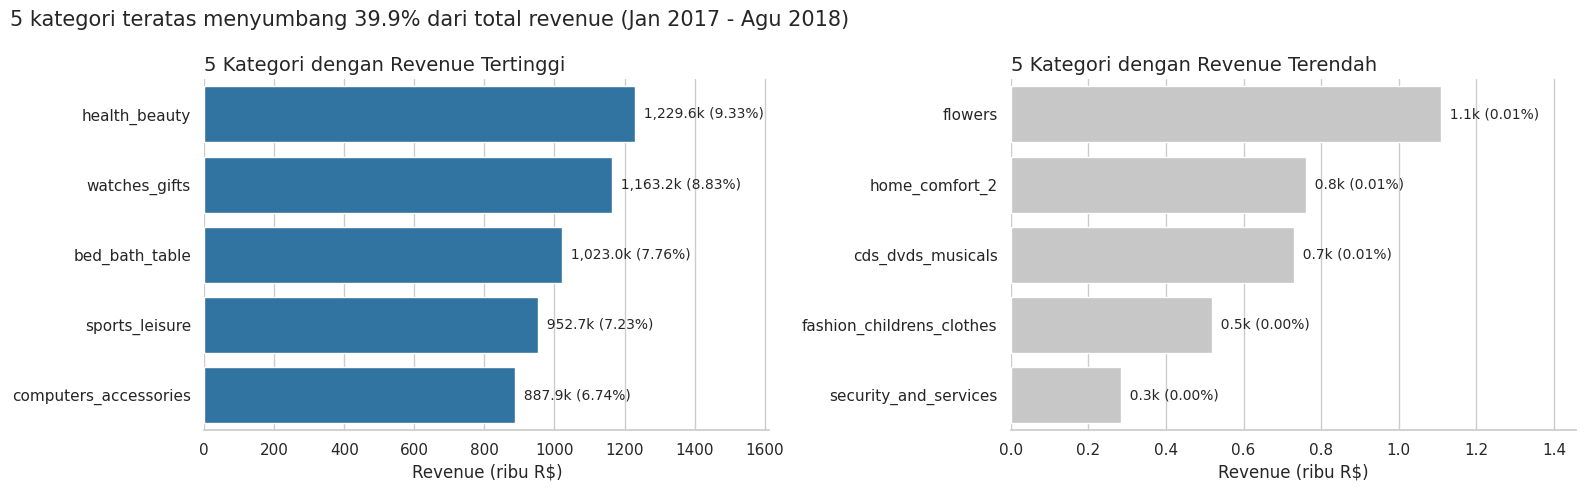

In [26]:
top5, bottom5 = category_df.head(5), category_df.tail(5)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(x=top5["revenue"] / 1e3, y=top5.index, color=HIGHLIGHT, ax=axes[0])
axes[0].set_title("5 Kategori dengan Revenue Tertinggi", fontsize=14, loc="left")
sns.barplot(x=bottom5["revenue"] / 1e3, y=bottom5.index, color=MUTED, ax=axes[1])
axes[1].set_title("5 Kategori dengan Revenue Terendah", fontsize=14, loc="left")

for ax, data in zip(axes, [top5, bottom5]):
    ax.set_xlabel("Revenue (ribu R$)"); ax.set_ylabel("")
    for i, (rev, share) in enumerate(zip(data["revenue"], data["share_pct"])):
        ax.text(rev / 1e3, i, f"  {rev / 1e3:,.1f}k ({share:.2f}%)", va="center", fontsize=10)
    ax.set_xlim(0, ax.get_xlim()[1] * 1.25)
    sns.despine(ax=ax, left=True)

top5_share = top5["share_pct"].sum()
fig.suptitle(f"5 kategori teratas menyumbang {top5_share:.1f}% dari total revenue (Jan 2017 - Agu 2018)", fontsize=15, x=0.01, ha="left")
plt.tight_layout()
plt.show()

### Pertanyaan 2: Seberapa besar keterlambatan menurunkan review score, dan state mana yang paling sering terlambat?

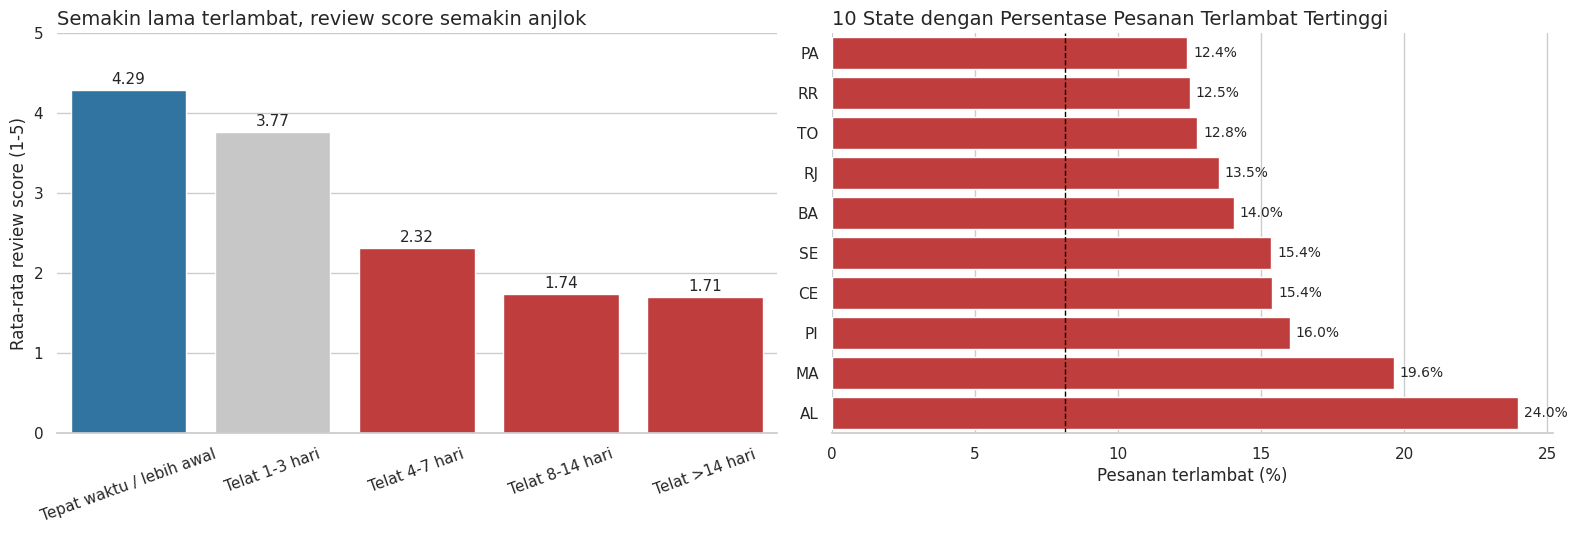

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# (a) Review score rata-rata per kelompok keterlambatan
colors = [HIGHLIGHT, MUTED, BAD, BAD, BAD]
sns.barplot(x=delay_review_df.index, y=delay_review_df["avg_review"], palette=colors, hue=delay_review_df.index, legend=False, ax=axes[0])
axes[0].set_title("Semakin lama terlambat, review score semakin anjlok", fontsize=14, loc="left")
axes[0].set_xlabel(""); axes[0].set_ylabel("Rata-rata review score (1-5)"); axes[0].set_ylim(0, 5)
axes[0].tick_params(axis="x", rotation=20)
for i, v in enumerate(delay_review_df["avg_review"]):
    axes[0].text(i, v + 0.07, f"{v:.2f}", ha="center", fontsize=11)

# (b) 10 state dengan persentase terlambat tertinggi
top_late = state_df.head(10).sort_values("late_pct")
overall_late = orders_level["is_late"].mean() * 100
sns.barplot(x=top_late["late_pct"], y=top_late.index, color=BAD, ax=axes[1])
axes[1].axvline(overall_late, color="black", linestyle="--", linewidth=1)
axes[1].set_title("10 State dengan Persentase Pesanan Terlambat Tertinggi", fontsize=14, loc="left")
axes[1].set_xlabel("Pesanan terlambat (%)"); axes[1].set_ylabel("")
for i, v in enumerate(top_late["late_pct"]):
    axes[1].text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=10)
sns.despine(left=True)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Kategori dengan revenue tertinggi adalah health_beauty (R\$1,23 juta, 9,33%) disusul watches_gifts (8,83%), bed_bath_table (7,76%), sports_leisure (7,23%), dan computers_accessories (6,74%). Lima kategori ini menyumbang 39,9% total revenue.
- watches_gifts mencapai posisi kedua dengan jumlah item lebih sedikit (5.853) dibanding bed_bath_table (10.945) karena harga rata-ratanya tinggi (R\$198,73 vs R\$93,46). Jadi revenue tinggi tidak selalu berarti volume tinggi.
- Kategori terendah (`security_and_services`, `fashion_childrens_clothes`, `cds_dvds_musicals`, `home_comfort_2`, `flowers`) masing-masing hanya menyumbang sekitar 0,01% atau kurang dengan kurang dari 35 item terjual.
- Keterlambatan sangat memengaruhi kepuasan: review turun dari 4,29 (tepat waktu) menjadi 3,77 (telat 1-3 hari), 2,32 (telat 4-7 hari), dan sekitar 1,7 (telat lebih dari 7 hari). Pada keterlambatan lebih dari 7 hari, sekitar 78% review bernilai 1-2, dibanding 9,2% pada pesanan tepat waktu.
- Terlambat 4 hari atau lebih adalah titik kritis, karena review turun di bawah 2,5.
- State dengan persentase terlambat tertinggi adalah AL (24,0%), MA (19,6%), PI (16,0%), CE (15,4%), dan SE (15,4%), jauh di atas rata-rata nasional 8,1%. Sembilan dari sepuluh state teratas berada di wilayah Timur Laut (Nordeste) dan Utara.
- RJ juga masuk 10 besar (13,5%) dan volumenya sangat besar (12.310 pesanan), sehingga dampaknya terhadap jumlah pelanggan kecewa paling besar.

## Analisis Lanjutan (Opsional)

Tiga teknik analisis lanjutan (tanpa machine learning) diterapkan karena relevan dengan data transaksi dan lokasi pelanggan:
1. **RFM Analysis**: mengelompokkan pelanggan berdasarkan *Recency* (hari sejak pembelian terakhir), *Frequency* (jumlah pesanan), dan *Monetary* (total belanja) untuk menentukan strategi retensi yang berbeda tiap segmen.
2. **Geospatial Analysis**: memetakan revenue dan persentase keterlambatan per state menurut titik koordinat agar pola wilayah terlihat jelas.
3. **Binning / Manual Grouping**: pengelompokan keterlambatan pengiriman (sudah dipakai pada Pertanyaan 2) dan penentuan segmen pelanggan berdasarkan aturan bisnis pada RFM.

### RFM Analysis

**RFM** mengelompokkan pelanggan menurut perilaku belanja berdasarkan `customer_unique_id`:
- **Recency**: jumlah hari sejak pembelian terakhir (semakin kecil semakin baik).
- **Frequency**: jumlah pesanan unik.
- **Monetary**: total belanja (R$).

Setiap metrik diberi skor 1-4 (4 = terbaik). Recency dan Monetary dibagi dengan kuartil (`pd.qcut`). Frequency memakai batas manual (`pd.cut`) karena sebagian besar pelanggan hanya membeli sekali. Segmen ditentukan dengan aturan bisnis (manual grouping):

| Segmen | Aturan |
|---|---|
| Loyal Aktif | Frequency >= 2 dan Recency skor >= 3 |
| Loyal Berisiko | Frequency >= 2 dan Recency skor <= 2 |
| Baru Bernilai Tinggi / Rendah | Beli sekali, Recency skor >= 3, Monetary skor >= 3 / < 3 |
| Dormant Bernilai Tinggi / Rendah | Beli sekali, Recency skor <= 2, Monetary skor >= 3 / < 3 |

Tujuannya agar tim marketing dapat menyusun strategi retensi yang berbeda untuk setiap segmen.

In [28]:
# Dasar RFM: satu baris per pelanggan unik
reference_date = all_data["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
rfm_df = (all_data.groupby("customer_unique_id")
          .agg(last_purchase=("order_purchase_timestamp", "max"), frequency=("order_id", "nunique"), monetary=("price", "sum"))
          .reset_index())
rfm_df["recency"] = (reference_date - rfm_df["last_purchase"]).dt.days
rfm_df = rfm_df.drop(columns="last_purchase")

# Skor 1-4 (4 = terbaik). Frequency didominasi 1x beli, sehingga memakai batas manual.
rfm_df["r_score"] = pd.qcut(rfm_df["recency"], 4, labels=[4, 3, 2, 1]).astype(int)
rfm_df["f_score"] = pd.cut(rfm_df["frequency"], bins=[0, 1, 2, 3, np.inf], labels=[1, 2, 3, 4]).astype(int)
rfm_df["m_score"] = pd.qcut(rfm_df["monetary"], 4, labels=[1, 2, 3, 4]).astype(int)

def segment(row):
    if row["f_score"] >= 2:
        return "Loyal Aktif" if row["r_score"] >= 3 else "Loyal Berisiko"
    if row["r_score"] >= 3:
        return "Baru Bernilai Tinggi" if row["m_score"] >= 3 else "Baru Bernilai Rendah"
    return "Dormant Bernilai Tinggi" if row["m_score"] >= 3 else "Dormant Bernilai Rendah"

rfm_df["segment"] = rfm_df.apply(segment, axis=1)
rfm_summary = (rfm_df.groupby("segment")
               .agg(customers=("customer_unique_id", "count"), avg_recency=("recency", "mean"),
                    avg_frequency=("frequency", "mean"), avg_monetary=("monetary", "mean"), total_monetary=("monetary", "sum"))
               .sort_values("customers", ascending=False))
rfm_summary["customer_pct"] = rfm_summary["customers"] / rfm_summary["customers"].sum() * 100
rfm_summary["revenue_pct"] = rfm_summary["total_monetary"] / rfm_summary["total_monetary"].sum() * 100
rfm_summary.round(1)

,customers,avg_recency,avg_frequency,avg_monetary,total_monetary,customer_pct,revenue_pct
segment,,,,,,,
Dormant Bernilai Rendah,23318,362.0,1.0,47.2,1101038.2,25.0,8.4
Baru Bernilai Rendah,22780,111.2,1.0,47.0,1070841.5,24.5,8.1
Baru Bernilai Tinggi,22244,111.8,1.0,231.6,5151070.8,23.9,39.1
Dormant Bernilai Tinggi,21965,362.5,1.0,233.6,5131472.4,23.6,38.9
Loyal Aktif,1534,112.2,2.1,264.5,405677.4,1.6,3.1
Loyal Berisiko,1255,350.9,2.1,254.7,319677.6,1.3,2.4


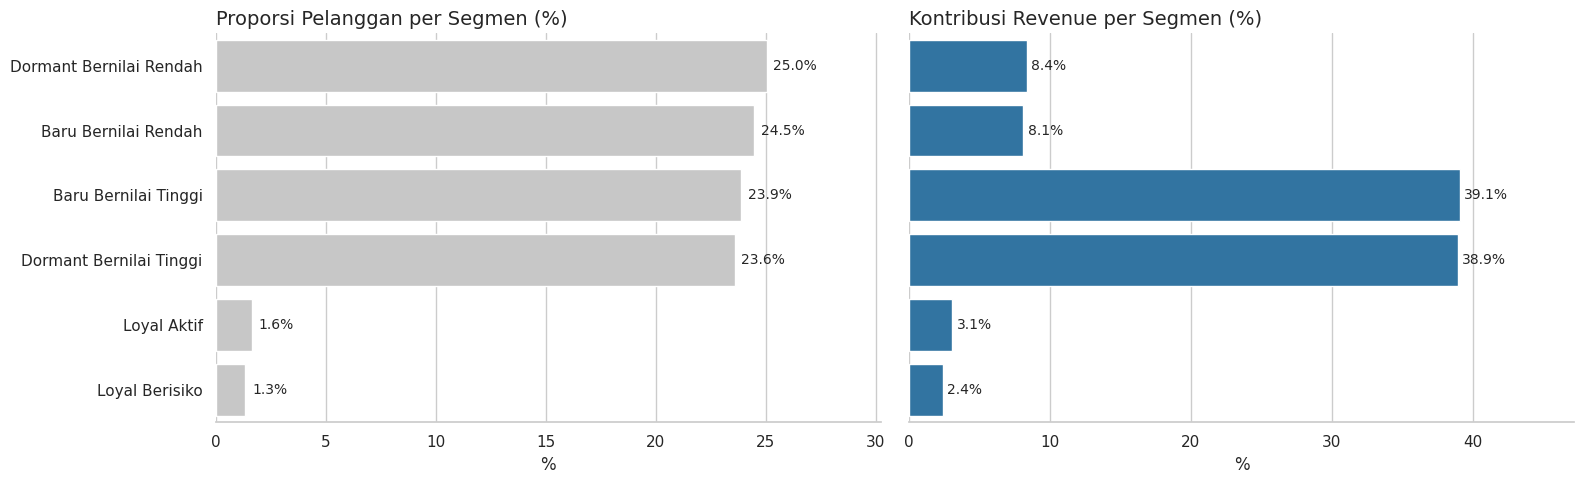

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
order = rfm_summary.index
sns.barplot(x=rfm_summary["customer_pct"], y=order, color=MUTED, ax=axes[0])
axes[0].set_title("Proporsi Pelanggan per Segmen (%)", fontsize=14, loc="left")
sns.barplot(x=rfm_summary["revenue_pct"], y=order, color=HIGHLIGHT, ax=axes[1])
axes[1].set_title("Kontribusi Revenue per Segmen (%)", fontsize=14, loc="left")
for ax, col in zip(axes, ["customer_pct", "revenue_pct"]):
    ax.set_xlabel("%"); ax.set_ylabel("")
    for i, v in enumerate(rfm_summary[col]):
        ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=10)
    ax.set_xlim(0, ax.get_xlim()[1] * 1.15)
    sns.despine(ax=ax, left=True)
axes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Hampir semua pelanggan hanya membeli sekali: segmen Loyal (Aktif + Berisiko) hanya 2,9% pelanggan dengan kontribusi revenue 5,5%.
- Pelanggan bernilai tinggi (belanja rata-rata sekitar R$ 232) terbagi dua kelompok sama besar: **Baru Bernilai Tinggi** (23,9% pelanggan, 39,1% revenue, recency sekitar 112 hari) dan **Dormant Bernilai Tinggi** (23,6% pelanggan, 38,9% revenue, recency sekitar 362 hari).
- Kedua segmen bernilai tinggi tersebut menyumbang 78% revenue sehingga menjadi target utama program retensi, sedangkan segmen bernilai rendah hanya menyumbang sekitar 8% revenue per segmen.

### Geospatial Analysis

Analisis geospasial memetakan metrik bisnis berdasarkan lokasi untuk menemukan pola wilayah. Setiap state digambarkan sebagai lingkaran pada koordinat pusatnya: **ukuran** lingkaran menunjukkan revenue, sedangkan **warna** (kuning ke merah) menunjukkan persentase pesanan terlambat. Dengan begitu terlihat wilayah mana yang besar sekaligus bermasalah dalam pengiriman.

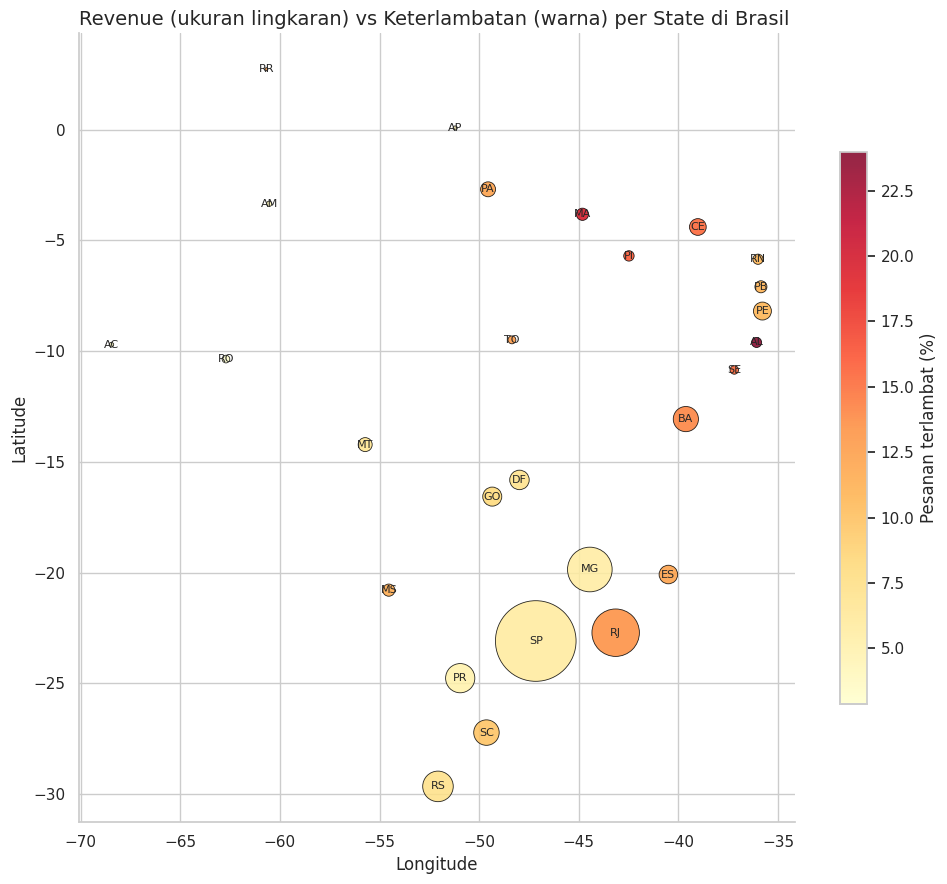

In [30]:
# Gabungkan metrik per state dengan titik koordinat pusat state
geo_df = (orders_level.groupby("customer_state")
          .agg(orders=("order_id", "count"), late_pct=("is_late", lambda s: s.mean() * 100)).reset_index()
          .merge(all_data.groupby("customer_state")["price"].sum().rename("revenue").reset_index(), on="customer_state")
          .merge(state_geo, on="customer_state"))

fig, ax = plt.subplots(figsize=(10, 9))
sc = ax.scatter(geo_df["lng"], geo_df["lat"], s=geo_df["revenue"] / 1500, c=geo_df["late_pct"],
                cmap="YlOrRd", edgecolor="black", linewidth=0.6, alpha=0.85)
for _, r in geo_df.iterrows():
    ax.annotate(r["customer_state"], (r["lng"], r["lat"]), ha="center", va="center", fontsize=8)
cbar = plt.colorbar(sc, ax=ax, shrink=0.7); cbar.set_label("Pesanan terlambat (%)")
ax.set_title("Revenue (ukuran lingkaran) vs Keterlambatan (warna) per State di Brasil", fontsize=14, loc="left")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
sns.despine()
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Revenue sangat terpusat di Tenggara: SP 38,4%, RJ 13,3%, MG 11,7%, RS 5,5%, PR 5,0%.
- Gelembung terang (keterlambatan tinggi) berada di Timur Laut Brasil (AL, MA, PI, CE, SE, BA), yaitu wilayah yang jauh dari pusat penjual di SP. Gelembungnya kecil karena kontribusi revenue-nya masih rendah, artinya ada potensi pasar jika layanan pengiriman diperbaiki.
- SP memiliki revenue terbesar sekaligus tingkat keterlambatan rendah (5,9%), sedangkan RJ memiliki keterlambatan 13,5% pada revenue terbesar kedua sehingga menjadi wilayah prioritas perbaikan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Total revenue dihitung hanya dari harga produk (`price`), tanpa ongkir (`freight_value`), pada pesanan *delivered* periode Januari 2017 - Agustus 2018, yaitu **R\$ 13,18 juta**.
  - **Revenue tertinggi:** `health_beauty` sebesar **R\$ 1.229.558** (9,33%).
  - **Revenue terendah:** `security_and_services` sebesar **R\$ 283** (0,002%) dengan hanya 2 item terjual.
  - **Revenue 5 kategori teratas:**

    | Peringkat | Kategori | Revenue (R\$) | Kontribusi |
    |---|---|---|---|
    | 1 | `health_beauty` | 1.229.558 | 9,33% |
    | 2 | `watches_gifts` | 1.163.188 | 8,83% |
    | 3 | `bed_bath_table` | 1.022.956 | 7,76% |
    | 4 | `sports_leisure` | 952.661 | 7,23% |
    | 5 | `computers_accessories` | 887.945 | 6,74% |

  - Lima kategori teratas bersama-sama menghasilkan **R\$ 5.256.307 atau 39,9%** dari total revenue, sehingga menjadi prioritas stok, promosi, dan akuisisi seller.
  - **5 kategori terendah:** `flowers` (R\$ 1.110), `home_comfort_2` (R\$ 760), `cds_dvds_musicals` (R\$ 730), `fashion_childrens_clothes` (R\$ 520), dan `security_and_services` (R\$ 283), masing-masing menyumbang kurang dari 0,01% dengan kurang dari 35 item terjual.
- **Conclusion pertanyaan 2:** Keterlambatan pengiriman menurunkan rata-rata review score dari **4,29** (tepat waktu) menjadi **2,57** (terlambat), yaitu **turun 1,72 poin atau sekitar 40,1%**. Bila terlambat lebih dari 7 hari, rata-rata review hanya sekitar 1,7.
  - Persentase keterlambatan dihitung per state: jumlah pesanan terlambat dibagi total pesanan *delivered* di state yang sama. Rata-rata nasional adalah 8,13%.
  - **10 state dengan persentase pesanan terlambat tertinggi:**

    | Peringkat | State | Pesanan terlambat | Total pesanan | % Terlambat |
    |---|---|---|---|---|
    | 1 | AL | 95 | 396 | 24,0% |
    | 2 | MA | 140 | 713 | 19,6% |
    | 3 | PI | 76 | 475 | 16,0% |
    | 4 | CE | 196 | 1.273 | 15,4% |
    | 5 | SE | 51 | 332 | 15,4% |
    | 6 | BA | 457 | 3.253 | 14,0% |
    | 7 | RJ | 1.664 | 12.310 | 13,5% |
    | 8 | TO | 35 | 274 | 12,8% |
    | 9 | RR | 5 | 40 | 12,5% |
    | 10 | PA | 117 | 942 | 12,4% |

- **Analisis lanjutan:** RFM menunjukkan 97,1% pelanggan hanya membeli sekali, dan 78% revenue berasal dari pelanggan bernilai tinggi yang separuhnya sudah dormant (tidak membeli sekitar 1 tahun). Analisis geospasial menunjukkan revenue terpusat di Tenggara sementara keterlambatan paling parah di Timur Laut.

**Rekomendasi Action Item:**
- **Memprioritaskan stok dan promosi pada 5 kategori teratas**, terutama `health_beauty` dan `watches_gifts` yang bernilai transaksi tinggi. Gunakan bundling atau cross-selling untuk menaikkan nilai pesanan, dan evaluasi kategori dengan kontribusi hampir nol (keputusan stop atau tingkatkan promosi).
- **Memasang target pengiriman maksimal 3 hari lewat estimasi** dan buat peringatan dini (alert) untuk pesanan yang diperkirakan terlambat lebih dari 3 hari. Beri kompensasi proaktif (voucher atau notifikasi) agar review tidak jatuh di bawah 2,5.
- **Memperbaiki logistik di AL, MA, PI, CE, SE, dan BA**: tambah mitra kurir regional, perluas gudang atau cross-docking, dan realistiskan estimasi pengiriman. Prioritaskan juga RJ karena volumenya besar dengan keterlambatan 13,5%.
- **Menjalankan kampanye reaktivasi untuk segmen Dormant Bernilai Tinggi** (sekitar 22 ribu pelanggan, 38,9% revenue), misalnya voucher personal pada kategori yang pernah dibeli, serta program insentif pembelian kedua untuk segmen Baru Bernilai Tinggi sebelum menjadi dormant.